# 01 · What customers complain about, and what it costs in stars

**Question for this notebook:** which problems drive low ratings, and which strengths
do happy customers mention? The answer feeds two things later on:
1. the *Review Highlights* feature we A/B test in notebooks 02-04, and
2. the marketing recommendation (what to promise, and what not to).

**About the data.** 3,000 reviews of 60 restaurants. The latent structure (star
rating, channel, which complaints happened) is sampled first from a J-shaped
distribution that mirrors real platforms (`src/generation.py`); the text is then
written by an LLM (`scripts/generate_reviews_llm.py`) or by the offline template
fallback. The `true_*` columns are **hidden from the pipeline** and only used at
the end to score it.

> **Read this before trusting any accuracy number below.** Synthetic text is easier
> than real text. If the data was written by the offline templates (check the `model`
> column), every score here is an upper bound. Rerun with the LLM generator for a
> harder corpus, and on real data, hand-label ~300 reviews.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import REVIEWS_CSV, REVIEWS_ENRICHED
from src.generation import COMPLAINTS, PRAISES
from src.nlp import sentiment, topics, complaints
from src.plotting import *

setup()
pd.set_option("display.width", 140, "display.max_colwidth", 110, "display.precision", 3)

df = pd.read_csv(REVIEWS_CSV)
print(f"{len(df):,} reviews · {df.restaurant_id.nunique()} restaurants · text source: {df.model.unique().tolist()}")
df[["restaurant_name", "cuisine", "channel", "rating", "text"]].sample(5, random_state=3)

3,000 reviews · 60 restaurants · text source: ['offline-templates']


,restaurant_name,cuisine,channel,rating,text
1283,Old House,Mexican,delivery,4,Best burrito in the neighborhood! eW waited forever for the delivery.
250,Golden Bistro,Burgers,delivery,5,Loved it! The smash burger tasted incredible... Also not worth the money!
2153,Casa Kitchen,Brazilian,delivery,5,Amazing! The staff was super friendly! Amazing flavor! My new faovrite.
2786,Golden Garden,Mexican,dine_in,4,Pretty good! It was raining. The food was delicious! But the staff was super friendly. Recommended.
632,Nonna's Table,Pizza,delivery,5,Amazing! Also way too expensive for what you get. And arrived earlier than expected... Also amazing flavor.


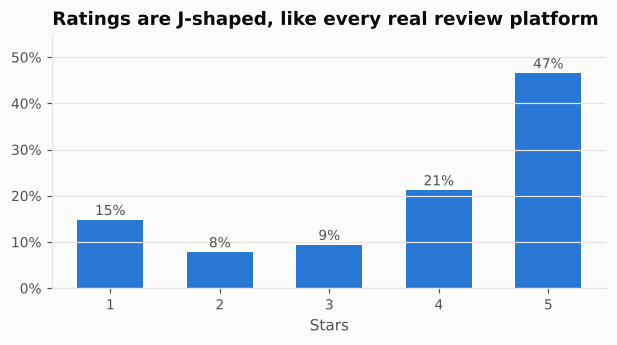

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 3))
share = df.rating.value_counts(normalize=True).sort_index()
ax.bar(share.index, share.values, color=BLUE, width=0.6)
for x, v in share.items():
    ax.text(x, v + 0.01, f"{v:.0%}", ha="center", color=INK_2, fontsize=9)
ax.set_title("Ratings are J-shaped, like every real review platform")
ax.set_xlabel("Stars"); pct(ax); ax.set_ylim(0, 0.55)
save(fig, "01_rating_distribution")

The mean rating (≈3.9) hides the shape: almost half are 5★, and the next biggest
group after 4★ is the angry 1★ bump. Averages of J-shaped data are a poor summary,
which is why we look at *what* people complain about rather than the mean.

## 1. Sentiment
Stars are already a sentiment label, so why model sentiment from text?
Because the text catches what stars flatten: mixed reviews ("great pasta, driver was
rude"), sarcasm, and polite-but-angry reviewers. Two approaches:
* **VADER**: an off-the-shelf lexicon model. No training, but generic.
* **TF-IDF + logistic regression**, trained to predict the star bucket (5-fold, out-of-fold predictions).

In [3]:
df, metrics = sentiment.run(df)
pd.Series(metrics).to_frame("value")

,value
spearman_vader_vs_stars,0.721
spearman_p,0.000
vader_macro_f1,0.612
supervised_macro_f1,0.965


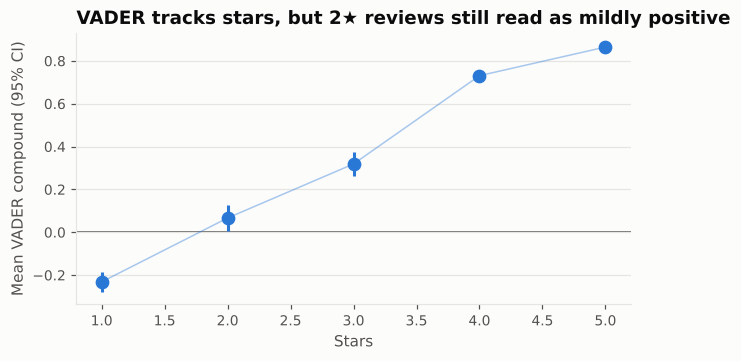

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
g = df.groupby("rating").vader_compound
m, se = g.mean(), g.sem()
ax.errorbar(m.index, m.values, yerr=1.96 * se.values, fmt="o", color=BLUE, ms=8, capsize=0, lw=2)
ax.plot(m.index, m.values, color=BLUE, lw=1, alpha=0.4)
zero_line(ax)
ax.set_title("VADER tracks stars, but 2★ reviews still read as mildly positive")
ax.set_xlabel("Stars"); ax.set_ylabel("Mean VADER compound (95% CI)")
save(fig, "01_vader_vs_stars")

**Reading it straight:** VADER correlates with stars (Spearman ≈ 0.7) but its macro-F1
against the star buckets is mediocre. The reason is visible above: 2★ reviews average a
*positive* score. Complaint language like "took ages to arrive" or "the ETA kept going up"
has no negative words in a general-purpose lexicon. The supervised model is far better here,
but on template text that is expected and partly flattering (see the warning at the top).

Where text and stars disagree is where the interesting reviews are:

In [5]:
sentiment.disagreements(df, n=6)

,rating,vader_compound,text
2350,4,-0.519,Solid choice. Nice music and decor... Also the price wentu p but the quality did not. Best acai bowl in th...
2318,4,-0.461,Solid choice. Plus the price went up but the quality did not. Super quick delivery! Recommended.
637,2,0.402,Not great. The portion was tiny... The food was delicious! Might give it another chance.
1140,2,0.402,"pretty disappointing. it was food. loved waiting, said no one ever."
1570,2,0.402,"Meh. Got someone else's order. We waited forever for the delivery... Plus overpriced, honestly."
2666,2,0.402,"Pretty disappointing. I've been here a few times. Had the buddha bowl. Loved waiting, said no one ever."


## 2. Topic modeling
Design choices, each one a lesson from a first attempt that failed:
* **Sentence level, not review level.** A review mixes aspects; whole-review topics came out as
  "positive review", "negative review". Splitting into sentences lets a topic mean *one thing*.
* **Complaint sentences only** (from ≤3★ reviews, VADER ≤ 0.3). On the full corpus the 66% of
  4-5★ reviews dominated and every topic was a flavor of praise.
* **Evaluative filler words removed** ("never again", "highly recommend"). They carry sentiment,
  not an aspect, and otherwise become their own topics.
* **NMF instead of LDA**: more stable on short text.

8,880 sentences → 2,390 complaint-candidate sentences


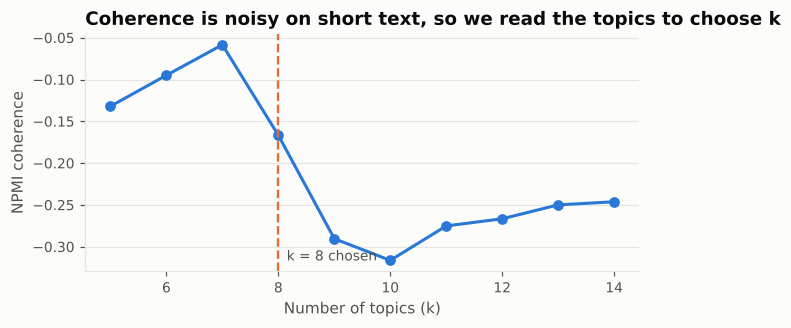

In [6]:
sents = sentiment.add_vader(topics.split_sentences(df), text_col="sentence")
neg = sents[(sents.rating <= 3) & (sents.vader_compound <= 0.3)].reset_index(drop=True)
print(f"{len(sents):,} sentences → {len(neg):,} complaint-candidate sentences")

grid = topics.choose_k(neg.sentence, ks=range(5, 15))
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(grid.k, grid.npmi, "o-", color=BLUE, ms=6)
ax.axvline(8, color=ORANGE, lw=1.5, ls="--")
ax.text(8.15, grid.npmi.min(), "k = 8 chosen", color=INK_2, fontsize=9)
ax.set_title("Coherence is noisy on short text, so we read the topics to choose k")
ax.set_xlabel("Number of topics (k)"); ax.set_ylabel("NPMI coherence")
save(fig, "01_topic_k_selection")

**Why not just take the k with the best coherence?** Because coherence is a proxy, and on short
reviews it is noisy. So we read the candidates:
* **k = 7** (best NPMI) merges "missing items" into a price topic: two problems owned by
  different teams in one bucket.
* **k = 8** separates them and every topic is still a real complaint.
* **k ≥ 9** starts producing filler topics built on words like "raining", "group of four",
  "used a coupon": they co-occur reliably but describe nothing a manager can fix. See k = 12:

In [7]:
W12, top12 = topics.fit_nmf(neg.sentence, 12)
filler = topics.suggest_labels(neg.sentence, W12, complaints.tag, COMPLAINTS)
filler["top_words"] = [", ".join(t[:6]) for t in top12]
filler[filler.suggested_label == "mixed_or_filler"]

,topic,suggested_label,purity,also_contains,top_words
8,8,mixed_or_filler,0.2,,"times, poisoning, work, group, portion, tiny"
9,9,mixed_or_filler,0.0,,"raining, group, portion, portion tiny, tiny, barely"


In [8]:
K = 8
W, top_words = topics.fit_nmf(neg.sentence, K)
labels = topics.suggest_labels(neg.sentence, W, complaints.tag, COMPLAINTS)
labels["top_words"] = [", ".join(t[:6]) for t in top_words]
labels["sentences"] = (W > 0.05).sum(0)
labels["mean_rating"] = [neg.rating[W[:, j] > 0.05].mean() for j in range(K)]
labels

,topic,suggested_label,purity,also_contains,top_words,sentences,mean_rating
0,0,cold_food,1.000,,"cold, arrived cold, arrived, fries soggy, fries, soggy cold",149,1.631
1,1,delivery_delay,1.000,,"delivery, late, late delivery, forever, forever delivery, waited forever",149,1.617
2,2,price_value,0.967,,"worth, money, worth money, th, forever, rolled",65,2.092
3,3,price_value,0.867,,"price, went, price went, quality, went quality, portions",128,2.203
4,4,rude_staff,1.000,,"staff, unfriendly, attitude, attitude staff, unfriendly attitude, rude",166,1.355
5,5,price_value,0.883,,"expensive, times, raining, poisoning, portion, tiny",53,2.283
6,6,order_accuracy,0.833,,"half, forgot half, forgot, delivery took, hour, hour half",89,1.528
7,7,order_accuracy,1.000,,"items, missing, cutlery, missing items, napkins, napkins cutlery",140,1.671


**What the topic model got right, and what it missed:**
* It found delivery delays, cold food, missing items, rude staff, and three flavors of price/value
  complaints without being told any category names.
* The "half, forgot, hour" topic mixes "forgot **half** the order" with "took an hour and a
  **half**": NMF groups by shared words, not meaning. Classic failure, and the reason a human
  reads the topics instead of trusting the auto-suggested label.
* **Hygiene never gets a topic of its own** (its words only leak into the tail of a price topic),
  and dine-in wait complaints vanish entirely. Hygiene is in ~2% of reviews, too rare to form a
  topic, yet it is the problem that gets a restaurant shut down.

That last point is the real takeaway: **topic models find the big themes and miss rare,
severe ones.** A business taxonomy needs every category ops acts on, with measurable
precision and recall. So we build one.

## 3. Complaint categories, validated, then tied to ratings

In [9]:
tags = complaints.tag(df.text)
ev = complaints.evaluate(df, tags)
ev

,category,kind,support,precision,recall,f1
0,delivery_delay,complaint,353,0.867,0.997,0.928
1,cold_food,complaint,202,1.000,0.995,0.998
2,order_accuracy,complaint,279,1.000,0.982,0.991
3,rude_staff,complaint,191,1.000,0.984,0.992
4,price_value,complaint,434,1.000,0.982,0.991
5,small_portion,complaint,237,1.000,0.996,0.998
6,hygiene,complaint,56,1.000,0.982,0.991
7,long_wait_dinein,complaint,117,1.000,1.000,1.000
8,taste,praise,1918,1.000,0.935,0.967
9,friendly_staff,praise,903,1.000,0.996,0.998


Precision/recall are near-perfect on most categories, which on template text proves the
plumbing works, not that the lexicon is good. `delivery_delay` precision (≈0.86) is the
honest number to look at: words like "late" fire on "ordered late at night". On LLM or real
text, expect every row to drop; the upgrade path is a zero-shot LLM classifier scored against
a hand-labelled set (README).

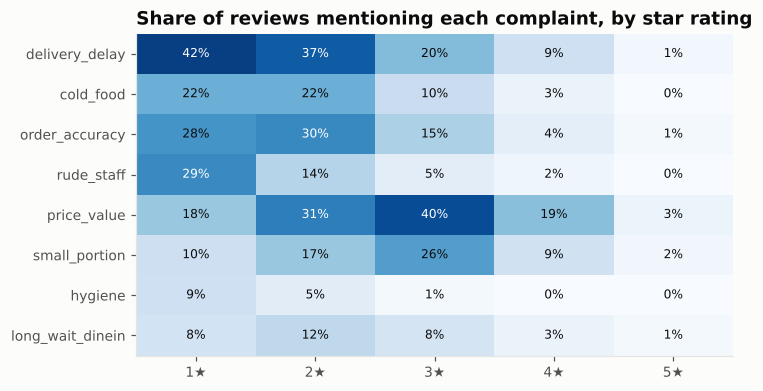

In [10]:
prev = complaints.prevalence_by_rating(df, tags)
fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(prev.values, cmap="Blues", aspect="auto", vmin=0, vmax=0.45)
ax.set_xticks(range(5), [f"{s}★" for s in prev.columns]); ax.set_yticks(range(len(prev)), prev.index)
for i in range(prev.shape[0]):
    for j in range(prev.shape[1]):
        v = prev.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.28 else INK)
ax.grid(False); ax.set_title("Share of reviews mentioning each complaint, by star rating")
save(fig, "01_complaints_by_rating")

Two shapes to notice: delivery delay, order accuracy and rude staff fall off a cliff as
stars rise (they *cause* 1★ reviews), while **price/value peaks at 3★**: people grumble about
price and still give a passable rating. A star average would never show that difference.

How many stars is each complaint worth? OLS of rating on all complaint flags together,
controlling for channel and price tier, with robust SEs:

In [11]:
impact, ols = complaints.star_impact(df, tags)
pm = complaints.priority_matrix(df, tags, impact)
print(f"R² = {ols.rsquared:.2f}")
pm

R² = 0.48


,star_impact,prevalence,share_of_1_2_star_reviews,stars_lost_per_100_reviews
delivery_delay,-1.207,0.135,0.405,16.336
order_accuracy,-1.199,0.091,0.283,10.947
rude_staff,-1.554,0.063,0.239,9.741
cold_food,-1.284,0.067,0.225,8.601
price_value,-0.519,0.142,0.223,7.374
small_portion,-0.561,0.079,0.123,4.416
hygiene,-1.258,0.018,0.078,2.307
long_wait_dinein,-0.560,0.039,0.097,2.186


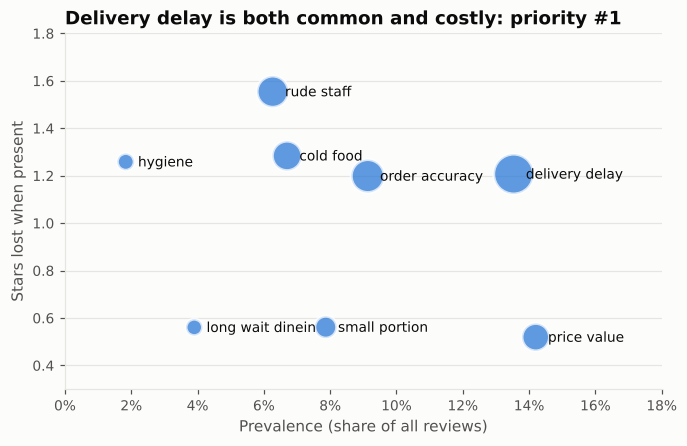

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.2))
x, y = pm.prevalence, -pm.star_impact
ax.scatter(x, y, s=pm.stars_lost_per_100_reviews * 40 + 30, color=BLUE, alpha=0.75,
           edgecolor="white", linewidth=2, zorder=3)
for name, r in pm.iterrows():
    ax.annotate(name.replace("_", " "), (r.prevalence, -r.star_impact), xytext=(8, -3),
                textcoords="offset points", fontsize=9, color=INK)
ax.set_xlabel("Prevalence (share of all reviews)"); ax.set_ylabel("Stars lost when present")
pct(ax, "x"); ax.set_xlim(0, 0.18); ax.set_ylim(0.3, 1.8)
ax.set_title("Delivery delay is both common and costly: priority #1")
save(fig, "01_priority_matrix")

**Ranking by stars lost per 100 reviews** (frequency × severity):
* **Delivery delay is the #1 problem**: in ~41% of 1-2★ reviews, costs ≈1.2★ when present.
* Rude staff is the most *severe* per mention (≈1.5★) but less frequent.
* Price/value is the most *frequent* complaint overall but cheap in stars (≈0.5★).
* Hygiene's coefficient (≈1.3★) is understated: those reviews already sit at the 1★ floor
  and come bundled with other complaints, so a linear model on a bounded scale can't show the
  full damage. Severe-but-rare problems need an alert, not a regression coefficient.

This is association, not causation. Someone already angry about a late order may also
notice the food is cold. That is exactly why the next step is an experiment.

## 4. From praise tags to the feature we will test
The same tagger finds praise. For each restaurant we take the top two praised aspects plus
the most common complaint, and render a **Review Highlights** card. Including one honest caveat
is a deliberate product choice: users distrust all-positive summaries.

In [13]:
PRAISE_TEXT = {"taste": "the food's flavor", "friendly_staff": "friendly staff", "fast_delivery": "fast delivery",
               "good_value": "good value", "generous_portion": "generous portions", "ambience": "the atmosphere"}
COMPLAINT_TEXT = {"delivery_delay": "late deliveries", "cold_food": "food arriving cold",
                  "order_accuracy": "missing items", "rude_staff": "staff attitude", "price_value": "prices",
                  "small_portion": "portion size", "hygiene": "cleanliness", "long_wait_dinein": "slow service"}

by_rest = pd.concat([df[["restaurant_name"]], tags], axis=1).groupby("restaurant_name").mean()
def highlight(name):
    r = by_rest.loc[name]
    p = r[PRAISES].sort_values(ascending=False).head(2)
    c = r[COMPLAINTS].sort_values(ascending=False).head(1)
    praise = " and ".join(f"{PRAISE_TEXT[k]} ({v:.0%})" for k, v in p.items())
    return f"{name}: reviewers love {praise}. Heads-up: {c.iloc[0]:.0%} mention {COMPLAINT_TEXT[c.index[0]]}."

for name in by_rest.sample(3, random_state=5).index:
    print("•", highlight(name))

• Little Bistro: reviewers love the food's flavor (72%) and friendly staff (34%). Heads-up: 11% mention late deliveries.
• Nonna's Spoon: reviewers love the food's flavor (52%) and friendly staff (17%). Heads-up: 21% mention late deliveries.
• Little House: reviewers love the food's flavor (58%) and friendly staff (23%). Heads-up: 21% mention late deliveries.


In [14]:
enriched = pd.concat([df, tags.add_prefix("tag_")], axis=1)
REVIEWS_ENRICHED.parent.mkdir(parents=True, exist_ok=True)
enriched.to_csv(REVIEWS_ENRICHED, index=False)
print(f"saved {REVIEWS_ENRICHED.relative_to(Path.cwd().parent)}")

saved data/processed/reviews_enriched.csv


## Takeaways
1. **Delivery delay is the costliest complaint** (frequency × severity). That is an operations
   problem, and marketing should not paper over it with speed claims (see notebook 04).
2. **Price complaints are frequent but mild**, concentrated in 3★ reviews: a value-perception
   problem, not a churn trigger.
3. **Topic models miss rare, severe issues** (hygiene). Use them to discover, a validated
   taxonomy to measure, and an alert for anything severe.
4. The praise side gives us a product idea, **Review Highlights**, whose effect we can test.